In [ ]:
# --- Cell 1: Mount Drive ---
from google.colab import drive
drive.mount('/content/drive')

import os
import zipfile
import shutil
from tqdm import tqdm
import pandas as pd
from PIL import Image

Mounted at /content/drive


In [ ]:
# --- Cell 2: Copy merged zip to local disk (already merged from before) ---
combined_path = '/content/drive/MyDrive/capstone-vehicle-metadata/data/compcars_sv/sv_combined.zip'
local_zip_path = '/content/sv_combined.zip'

!cp "{combined_path}" "{local_zip_path}"
print("Copied.")

Copied.


In [ ]:
combined_path = '/content/drive/MyDrive/capstone-vehicle-metadata/data/compcars_sv/sv_combined.zip'
local_zip_path = '/content/sv_combined.zip'

print(f"Drive version size: {os.path.getsize(combined_path) / (1024*1024):.1f} MB")
print(f"Local version size: {os.path.getsize(local_zip_path) / (1024*1024):.1f} MB")

Drive version size: 0.0 MB
Local version size: 0.0 MB


In [ ]:
os.remove(local_zip_path)
!cp "{combined_path}" "{local_zip_path}"

# Verify sizes match this time
print(f"Drive version size: {os.path.getsize(combined_path) / (1024*1024):.1f} MB")
print(f"Local version size: {os.path.getsize(local_zip_path) / (1024*1024):.1f} MB")

Drive version size: 0.0 MB
Local version size: 0.0 MB


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

raw_parts_dir = '/content/drive/MyDrive/capstone-vehicle-metadata/data/compcars_sv/raw_parts'
files = sorted(os.listdir(raw_parts_dir))
print(f"Total files: {len(files)}")
for f in files:
    size_mb = os.path.getsize(os.path.join(raw_parts_dir, f)) / (1024*1024)
    print(f"{f} - {size_mb:.1f} MB")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Total files: 4
sv_data.z01 - 700.0 MB
sv_data.z02 - 700.0 MB
sv_data.z03 - 700.0 MB
sv_data.zip - 307.5 MB


In [ ]:
source_dir = '/content/drive/MyDrive/CompCars'  # your shared folder, adjust name if needed
sv_files_in_source = [f for f in os.listdir(source_dir) if f.startswith('sv_data')]
print(sorted(sv_files_in_source))

['sv_data.z01', 'sv_data.z02', 'sv_data.z03', 'sv_data.zip']


In [ ]:
# Step 1: Copy raw parts to LOCAL disk first
import shutil

local_raw_parts = '/content/sv_raw_parts'
os.makedirs(local_raw_parts, exist_ok=True)

raw_parts_dir = '/content/drive/MyDrive/capstone-vehicle-metadata/data/compcars_sv/raw_parts'
for fname in os.listdir(raw_parts_dir):
    print(f"Copying {fname}...")
    shutil.copy(os.path.join(raw_parts_dir, fname), local_raw_parts)

print("Done copying parts locally.")

Copying sv_data.z01...
Copying sv_data.z02...
Copying sv_data.z03...
Copying sv_data.zip...
Done copying parts locally.


In [ ]:
# Step 2: Verify sizes match after copying
for f in os.listdir(local_raw_parts):
    size_mb = os.path.getsize(os.path.join(local_raw_parts, f)) / (1024*1024)
    print(f"{f} - {size_mb:.1f} MB")

sv_data.zip - 307.5 MB
sv_data.z03 - 700.0 MB
sv_data.z02 - 700.0 MB
sv_data.z01 - 700.0 MB


In [ ]:
# Step 3: Merge entirely on LOCAL disk (both source and output local)
!zip -F {local_raw_parts}/sv_data.zip --out /content/sv_combined_local.zip

Streaming output truncated to the last 5000 lines.
 copying: sv_data/image/73/562782c8cf70a6.jpg
 copying: sv_data/image/73/56f2f91badda2d.jpg
 copying: sv_data/image/73/57d10d3a32eb1a.jpg
 copying: sv_data/image/73/592493337750e7.jpg
 copying: sv_data/image/73/598ae25cd5b9f4.jpg
 copying: sv_data/image/73/5a0c024428a674.jpg
 copying: sv_data/image/73/5a23af839e1029.jpg
 copying: sv_data/image/73/5b0f288333d0c1.jpg
 copying: sv_data/image/73/5b27c3fa4a950f.jpg
 copying: sv_data/image/73/5b2962c1e14c9f.jpg
 copying: sv_data/image/73/5b2bbe007a9eee.jpg
 copying: sv_data/image/73/5b60d0d70ef437.jpg
 copying: sv_data/image/73/5c4f898c068d86.jpg
 copying: sv_data/image/73/5c7ecdc74cf057.jpg
 copying: sv_data/image/73/5d8f4b6fb8da9d.jpg
 copying: sv_data/image/73/5e10606b0b01cc.jpg
 copying: sv_data/image/73/5eecae3c351575.jpg
 copying: sv_data/image/73/5f27537818c39d.jpg
 copying: sv_data/image/73/5f7447c96b06bf.jpg
 copying: sv_data/image/73/5fcf2d8ffb21d9.jpg
 copying: sv_data/image/73/61

In [ ]:
# Step 4: Verify the LOCAL merge worked
print(f"Local merged size: {os.path.getsize('/content/sv_combined_local.zip') / (1024*1024):.1f} MB")

Local merged size: 2407.5 MB


In [ ]:
import zipfile
from tqdm import tqdm

local_sv_path = '/content/compcars_sv_local'

with zipfile.ZipFile('/content/sv_combined_local.zip', 'r') as zf:
    all_names = zf.namelist()
    print(f"Extracting {len(all_names)} files...")
    for name in tqdm(all_names, desc='Extracting sv_data'):
        zf.extract(name, path=local_sv_path, pwd=b'd89551fd190e38')

print("Done.")

Extracting 44769 files...


Extracting sv_data: 100%|██████████| 44769/44769 [1:06:59<00:00, 11.14it/s]

Done.


In [ ]:
local_count = sum(len(files) for _, _, files in os.walk(local_sv_path))
print(f"Extracted: {local_count}")

Extracted: 44486


In [ ]:
for root, dirs, files in os.walk(local_sv_path):
    print(root, '->', len(files), 'files', '| sample:', files[:5])

/content/compcars_sv_local -> 0 files | sample: []
/content/compcars_sv_local/sv_data -> 5 files | sample: ['README', 'test_surveillance.txt', 'sv_make_model_name.mat', 'train_surveillance.txt', 'color_list.mat']
/content/compcars_sv_local/sv_data/image -> 0 files | sample: []
/content/compcars_sv_local/sv_data/image/28 -> 131 files | sample: ['4122b6ab038366.jpg', '6e64ab2ec01e74.jpg', 'e986d17ccbd8c2.jpg', '2aa2c22d1a6edd.jpg', '73404735b4d197.jpg']
/content/compcars_sv_local/sv_data/image/211 -> 114 files | sample: ['2f63ba4efd1631.jpg', '3b55af302dca08.jpg', '0f84dc85e0bae0.jpg', 'fffb7ad3abd9b4.jpg', '8d727d91dc85b0.jpg']
/content/compcars_sv_local/sv_data/image/252 -> 197 files | sample: ['a79cd438427db3.jpg', '848e6c8f23ef2d.jpg', 'f274323892c9ed.jpg', '3bc3e9a7b4383b.jpg', 'e5cddd74adf530.jpg']
/content/compcars_sv_local/sv_data/image/177 -> 84 files | sample: ['7ed2b97875110e.jpg', 'b84026386513f6.jpg', 'e2e58af5553c73.jpg', 'c948a83a54e14e.jpg', '032b55568bbc85.jpg']
/content

In [ ]:
import zipfile

with zipfile.ZipFile('/content/sv_combined_local.zip', 'r') as zf:
    all_names = zf.namelist()
    folder_entries = [n for n in all_names if n.endswith('/')]
    file_entries = [n for n in all_names if not n.endswith('/')]
    print(f"Total entries: {len(all_names)}")
    print(f"Folder entries (not real files): {len(folder_entries)}")
    print(f"Actual file entries: {len(file_entries)}")

Total entries: 44769
Folder entries (not real files): 283
Actual file entries: 44486


In [ ]:
with open('/content/compcars_sv_local/sv_data/README') as f:
    print(f.read())

This part of data is the surveillance-nature data in the CompCars dataset.
(http://mmlab.ie.cuhk.edu.hk/datasets/comp_cars/index.html)

If you use the dataset in your work, please cite our CVPR 2015 paper:
Linjie Yang, Ping Luo, Chen Change Loy, Xiaoou Tang. "A Large-Scale Car Dataset for Fine-Grained Categorization and Verification", In Computer Vision and Pattern Recognition (CVPR), 2015.

Descriptions of the files are as follows:

-image:
  Stores all car images in the path format 'surveillance_model_id/image_name.jpg'.
-color_list.mat:
  A MATLAB cell matrix containing all color annotations for each image. Each row is the annotation for one image with the first element being the path of the image and the second element being the color id. The meaning of the color ids are: -1 - unrecognized, 0 - black, 1 - white, 2 - red, 3 - yellow, 4 - blue, 5 - green, 6 - purple, 7 - brown, 8 - champagne, 9 - silver.
-sv_make_model_name.mat:
  A MATLAB cell matrix containing make and model names 

In [ ]:
with open('/content/compcars_sv_local/sv_data/train_surveillance.txt') as f:
    train_lines = f.readlines()
print(f"Total lines: {len(train_lines)}")
print("First 10 lines:")
for line in train_lines[:10]:
    print(line.strip())

Total lines: 31148
First 10 lines:
1/431e8997607115.jpg
1/dd2be86b09ee47.jpg
1/6b83b0deca175f.jpg
1/bac6732569714e.jpg
1/f747ed14094d48.jpg
1/7c42ea6cb2e8ff.jpg
1/12e80f78dac16e.jpg
1/1ff86f438011ed.jpg
1/e83b1871001d23.jpg
1/83a96a94af573d.jpg


In [ ]:
from scipy.io import loadmat

sv_make_model = loadmat('/content/compcars_sv_local/sv_data/sv_make_model_name.mat')
print("Keys:", sv_make_model.keys())
for key in sv_make_model:
    if not key.startswith('__'):
        print(f"\n{key}: shape={sv_make_model[key].shape}, sample={sv_make_model[key][:5]}")

Keys: dict_keys(['__header__', '__version__', '__globals__', 'sv_make_model_name'])

sv_make_model_name: shape=(281, 3), sample=[[array(['Besturn'], dtype='<U7') array(['Besturn X80'], dtype='<U11')
  array([[366]], dtype=uint16)]
 [array(['Hafei'], dtype='<U5') array(['Lubao'], dtype='<U5')
  array([[716]], dtype=uint16)]
 [array(['Audi'], dtype='<U4') array(['Audi Q5'], dtype='<U7')
  array([[5]], dtype=uint8)]
 [array(['Audi'], dtype='<U4') array(['Audi Q3'], dtype='<U7')
  array([[4]], dtype=uint8)]
 [array(['Audi'], dtype='<U4') array(['Audi A7'], dtype='<U7')
  array([[26]], dtype=uint8)]]


In [ ]:
color_data = loadmat('/content/compcars_sv_local/sv_data/color_list.mat')
print("Keys:", color_data.keys())
for key in color_data:
    if not key.startswith('__'):
        print(f"\n{key}: shape={color_data[key].shape}, sample={color_data[key][:5]}")

Keys: dict_keys(['__header__', '__version__', '__globals__', 'color_list'])

color_list: shape=(44481, 2), sample=[[array(['1/d5dcefddcde927.jpg'], dtype='<U20') array([[1]], dtype=uint8)]
 [array(['1/a751752e438d65.jpg'], dtype='<U20') array([[2]], dtype=uint8)]
 [array(['1/c5f1d0a1f04fc9.jpg'], dtype='<U20') array([[9]], dtype=uint8)]
 [array(['1/874f996b927cff.jpg'], dtype='<U20') array([[0]], dtype=uint8)]
 [array(['1/74fe86d0eea1cc.jpg'], dtype='<U20') array([[1]], dtype=uint8)]]


In [ ]:
# --- Build surveillance_model_id -> (make, model, web_model_id) lookup ---
sv_make_model = loadmat('/content/compcars_sv_local/sv_data/sv_make_model_name.mat')['sv_make_model_name']

sv_id_to_info = {}
for i in range(len(sv_make_model)):
    row = sv_make_model[i]
    make = row[0][0] if row[0].size > 0 else None
    model = row[1][0] if row[1].size > 0 else None
    web_model_id = int(row[2][0][0]) if row[2].size > 0 else None
    sv_id_to_info[i+1] = {'make': make, 'model': model, 'web_model_id': web_model_id}

print(f"Total surveillance model IDs mapped: {len(sv_id_to_info)}")
print(sv_id_to_info[1])

Total surveillance model IDs mapped: 281
{'make': np.str_('Besturn'), 'model': np.str_('Besturn X80'), 'web_model_id': 366}


In [ ]:
# --- Build color lookup: image path -> color_id ---
color_data = loadmat('/content/compcars_sv_local/sv_data/color_list.mat')['color_list']

color_map = {}
color_names = {-1: 'unrecognized', 0: 'black', 1: 'white', 2: 'red', 3: 'yellow',
               4: 'blue', 5: 'green', 6: 'purple', 7: 'brown', 8: 'champagne', 9: 'silver'}

for i in range(len(color_data)):
    img_path = color_data[i][0][0]
    color_id = int(color_data[i][1][0][0])
    color_map[img_path] = color_names.get(color_id, 'unknown')

print(f"Total color entries: {len(color_map)}")
print(list(color_map.items())[:5])

Total color entries: 44481
[(np.str_('1/d5dcefddcde927.jpg'), 'white'), (np.str_('1/a751752e438d65.jpg'), 'red'), (np.str_('1/c5f1d0a1f04fc9.jpg'), 'silver'), (np.str_('1/874f996b927cff.jpg'), 'black'), (np.str_('1/74fe86d0eea1cc.jpg'), 'white')]


In [ ]:
# --- Build the full inventory, walking the image folder and joining labels ---
import pandas as pd
from PIL import Image
from tqdm import tqdm

sv_image_root = '/content/compcars_sv_local/sv_data/image'
records = []

for root, dirs, files in tqdm(list(os.walk(sv_image_root)), desc='Processing folders'):
    if not files:
        continue
    sv_model_id = int(os.path.basename(root))
    info = sv_id_to_info.get(sv_model_id, {})
    for fname in files:
        if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
            fpath = os.path.join(root, fname)
            rel_path = f"{sv_model_id}/{fname}"  # matches color_list.mat's path format
            try:
                with Image.open(fpath) as img:
                    width, height = img.size
                corrupted = False
            except Exception:
                width, height = None, None
                corrupted = True
            records.append({
                'file_path': fpath,
                'surveillance_model_id': sv_model_id,
                'make': info.get('make'),
                'model': info.get('model'),
                'web_model_id': info.get('web_model_id'),
                'color': color_map.get(rel_path, None),
                'width': width,
                'height': height,
                'corrupted': corrupted
            })

df_sv = pd.DataFrame(records)
print(f"Total: {len(df_sv)}")
print(f"Corrupted: {df_sv['corrupted'].sum()}")
print(f"Missing color: {df_sv['color'].isna().sum()}")

Processing folders: 100%|██████████| 282/282 [00:40<00:00,  6.99it/s]

Total: 44481
Corrupted: 0
Missing color: 0


In [ ]:
# --- Check counts against official stats ---
print(f"Total images: {len(df_sv)} (official: 50,000)")
print(f"Unique makes: {df_sv['make'].nunique()}")
print(f"Unique models: {df_sv['model'].nunique()}")
print(df_sv['color'].value_counts(dropna=False))

Total images: 44481 (official: 50,000)
Unique makes: 68
Unique models: 281
color
black           14911
silver          12569
white            7570
red              3627
blue             1876
brown            1460
yellow           1123
champagne         829
green             255
purple            221
unrecognized       40
Name: count, dtype: int64


In [ ]:
import hashlib
from tqdm import tqdm

def get_image_hash(filepath):
    try:
        with open(filepath, 'rb') as f:
            return hashlib.md5(f.read()).hexdigest()
    except Exception:
        return None

tqdm.pandas(desc='Hashing')
df_sv['image_hash'] = df_sv['file_path'].progress_apply(get_image_hash)
print(f"Duplicates: {df_sv['image_hash'].duplicated().sum()}")

Hashing: 100%|██████████| 44481/44481 [00:20<00:00, 2177.06it/s]

Duplicates: 0


In [ ]:
# Copy to Drive so paths persist and resolve for teammates
import shutil
drive_sv_path = '/content/drive/MyDrive/capstone-vehicle-metadata/data/compcars_sv/extracted'
shutil.copytree('/content/compcars_sv_local', drive_sv_path, dirs_exist_ok=True)
print("Copied to Drive.")

Copied to Drive.


In [ ]:
# Fix file paths to Drive location and save
df_sv['file_path'] = df_sv['file_path'].str.replace(
    '/content/compcars_sv_local',
    drive_sv_path,
    regex=False
)

df_sv['source_dataset'] = 'compcars_surveillance'

os.makedirs('/content/drive/MyDrive/capstone-vehicle-metadata/outputs', exist_ok=True)
df_sv.to_csv('/content/drive/MyDrive/capstone-vehicle-metadata/outputs/compcars_surveillance_inventory.csv', index=False)
print(f"Saved {len(df_sv)} rows.")

Saved 44481 rows.


In [ ]:
check = pd.read_csv('/content/drive/MyDrive/capstone-vehicle-metadata/outputs/compcars_surveillance_inventory.csv')
print(f"Rows: {len(check)}")
check.head()

Rows: 44481


,file_path,surveillance_model_id,make,model,web_model_id,color,width,height,corrupted,image_hash,source_dataset
0,/content/drive/MyDrive/capstone-vehicle-metada...,28,Benz,Benz S Class,162,black,715,694,False,a9f291899882db6abdec02b39e3e1c02,compcars_surveillance
1,/content/drive/MyDrive/capstone-vehicle-metada...,28,Benz,Benz S Class,162,black,853,814,False,d82153149248872ce3e4665a01c5d9e8,compcars_surveillance
2,/content/drive/MyDrive/capstone-vehicle-metada...,28,Benz,Benz S Class,162,black,846,836,False,8b7b7406c795e8b192357f59cf180886,compcars_surveillance
3,/content/drive/MyDrive/capstone-vehicle-metada...,28,Benz,Benz S Class,162,black,787,852,False,c1cf8e05a448ca8ca246945a3f24e8e7,compcars_surveillance
4,/content/drive/MyDrive/capstone-vehicle-metada...,28,Benz,Benz S Class,162,black,770,791,False,09196427a66499de172a1d706289499f,compcars_surveillance


In [ ]:
# Rebuild model_id -> body_type mapping from attributes.txt (same source as before)
misc_path = '/content/drive/MyDrive/capstone-vehicle-metadata/data/compcars_kaggle/extracted/misc'

attrs_df = pd.read_csv(
    os.path.join(misc_path, 'attributes.txt'),
    sep=' '
)

# Rebuild the type_id -> body_type lookup (same as your original web-nature code)
from scipy.io import loadmat

car_type_data = loadmat(os.path.join(misc_path, 'car_type.mat'))
types_raw = car_type_data['types'][0]
type_id_to_bodytype = {}

for i in range(len(types_raw)):
    entry = types_raw[i]
    if entry.size > 0:
        type_id_to_bodytype[i+1] = entry[0]
    else:
        type_id_to_bodytype[i+1] = None

attrs_df['body_type'] = attrs_df['type'].map(type_id_to_bodytype)

# Build the final model_id -> body_type dictionary
model_id_to_bodytype = attrs_df.set_index('model_id')['body_type'].to_dict()

print(f"Total model_id -> body_type mappings: {len(model_id_to_bodytype)}")
print(f"Sample: model_id 1 -> {model_id_to_bodytype.get(1)}")

Total model_id -> body_type mappings: 1716
Sample: model_id 1 -> hatchback


In [ ]:
df_sv['body_type'] = df_sv['web_model_id'].map(model_id_to_bodytype)

print(f"Total surveillance rows: {len(df_sv)}")
print(f"Rows with body_type: {df_sv['body_type'].notna().sum()}")
print(f"Missing body_type: {df_sv['body_type'].isna().sum()}")
print(df_sv['body_type'].value_counts(dropna=False))

Total surveillance rows: 44481
Rows with body_type: 41638
Missing body_type: 2843
body_type
sedan                  17740
SUV                    13186
hatchback               5346
MPV                     3480
NaN                     2843
minibus                  716
fastback                 436
sports                   417
hardtop convertible      162
estate                   106
crossover                 49
Name: count, dtype: int64


In [ ]:
df_sv.to_csv('/content/drive/MyDrive/capstone-vehicle-metadata/outputs/compcars_surveillance_inventory.csv', index=False)
print(f"Saved {len(df_sv)} rows with body_type included.")

Saved 44481 rows with body_type included.


In [ ]:
df_clean_with_id = pd.read_csv('/content/drive/MyDrive/capstone-vehicle-metadata/outputs/compcars_modeling_ready.csv')

def extract_model_id(fpath):
    parts = fpath.split('/')
    idx = parts.index('image')
    return int(parts[idx+2])

df_clean_with_id['model_id'] = df_clean_with_id['file_path'].apply(extract_model_id)

df_clean_with_id.to_csv('/content/drive/MyDrive/capstone-vehicle-metadata/outputs/compcars_modeling_ready.csv', index=False)
print(f"Updated with model_id. Columns now: {df_clean_with_id.columns.tolist()}")

Updated with model_id. Columns now: ['file_path', 'make', 'model_name', 'body_type', 'width', 'height', 'source_dataset', 'image_hash', 'model_id']


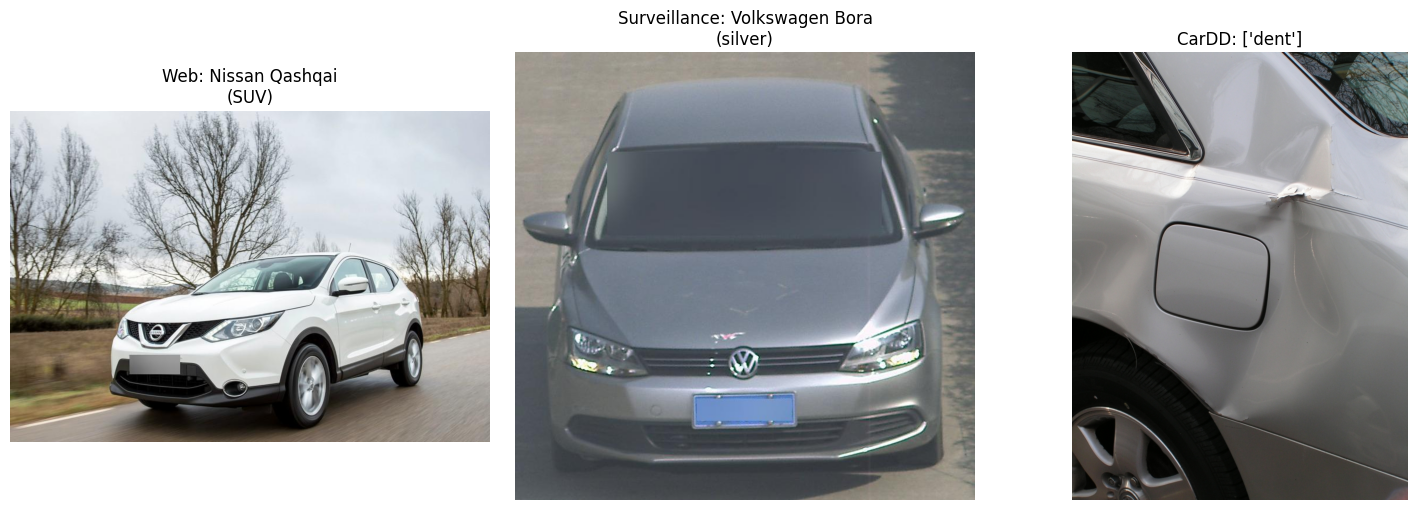

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# CompCars web-nature
web_sample = pd.read_csv('/content/drive/MyDrive/capstone-vehicle-metadata/outputs/compcars_modeling_ready.csv').sample(1).iloc[0]
img1 = Image.open(web_sample['file_path'])
axes[0].imshow(img1)
axes[0].set_title(f"Web: {web_sample['make']} {web_sample['model_name']}\n({web_sample['body_type']})")
axes[0].axis('off')

# CompCars surveillance
sv_sample = df_sv.sample(1).iloc[0]
img2 = Image.open(sv_sample['file_path'])
axes[1].imshow(img2)
axes[1].set_title(f"Surveillance: {sv_sample['make']} {sv_sample['model']}\n({sv_sample['color']})")
axes[1].axis('off')

# CarDD
cardd_sample = pd.read_csv('/content/drive/MyDrive/capstone-vehicle-metadata/outputs/cardd_inventory.csv').sample(1).iloc[0]
img3 = Image.open(cardd_sample['file_path'])
axes[2].imshow(img3)
axes[2].set_title(f"CarDD: {cardd_sample['damage_classes']}")
axes[2].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
!pip install rapidfuzz -q
from google.colab import drive
drive.mount('/content/drive')

import os, json, re
from collections import Counter
import pandas as pd
from rapidfuzz.distance import DamerauLevenshtein

out_dir = '/content/drive/MyDrive/capstone-vehicle-metadata/outputs'
sv = pd.read_csv(f'{out_dir}/compcars_surveillance_inventory.csv')
make_fixes = json.load(open(f'{out_dir}/make_fixes.json'))
model_fixes = json.load(open(f'{out_dir}/model_fixes.json'))

print(sv.shape)
print(sv.columns.tolist())
print(os.path.exists(f'{out_dir}/compcars_modeling_ready_v2.csv'), "<- web v2 must exist")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 18.2 MB/s eta 0:00:00
Mounted at /content/drive
(44481, 12)
['file_path', 'surveillance_model_id', 'make', 'model', 'web_model_id', 'color', 'width', 'height', 'corrupted', 'image_hash', 'source_dataset', 'body_type']
True <- web v2 must exist


In [ ]:
makes_stripped = sv['make'].str.strip()
for old, new in make_fixes.items():
    print(f"{old} -> {new}: {(makes_stripped == old).sum()} rows now, {(makes_stripped == new).sum()} already correct")

print("\nMakes with hidden whitespace:", [repr(m) for m in sv['make'].dropna().unique() if m != m.strip()])

BWM -> BMW: 1678 rows now, 0 already correct
Chrey -> Chery: 181 rows now, 0 already correct
Buck -> Buick: 740 rows now, 0 already correct
Saab -> SAAB: 0 rows now, 0 already correct
AC Chnitzer -> AC Schnitzer: 0 rows now, 0 already correct
Wisemann -> Wiesmann: 0 rows now, 0 already correct
Zoyte -> Zotye: 282 rows now, 0 already correct
Wealeak -> WeaLink: 0 rows now, 0 already correct
Lamorghini -> Lamborghini: 0 rows now, 0 already correct

Makes with hidden whitespace: ["'Hyundai '"]


In [ ]:
rows = []
for mk, g in sv.groupby(sv['make'].str.strip()):
    k = len(mk.split())
    prefixes = g['model'].dropna().str.split().str[:k].str.join(' ')
    if prefixes.empty:
        continue
    top, n = Counter(prefixes).most_common(1)[0]
    share = n / len(prefixes)
    edits = DamerauLevenshtein.distance(top.lower(), mk.lower())
    if top != mk and edits <= 2 and share >= 0.4:
        rows.append({'make': mk, 'models_start_with': top, 'share': round(share, 2), 'edits': edits, 'rows': len(g)})
print(pd.DataFrame(rows))

print("\nAll makes:")
print(sorted(sv['make'].str.strip().dropna().unique()))

     make models_start_with  share  edits  rows
0  Jaguar            Gaguar    1.0      1   230
1   MAZDA             Mazda    1.0      0  1626
2   Zoyte             Zotye    1.0      1   282

All makes:
['Acura', 'Audi', 'BWM', 'BYD', 'Baojun', 'Benz', 'Besturn', 'Buck', 'Cadillac', 'Changan', 'Changhe', 'Chevy', 'Chrey', 'Chrysler', 'Citroen', 'Dodge', 'Dongfengfengdu', 'Dongfengfengshen', 'Everus', 'FIAT', 'Ford', 'GAC', 'Geely', 'GreatWall', 'Guangqichuanqi', 'Hafei', 'Haima', 'Haima(Zhengzhou)', 'Haval', 'Honda', 'Huanghai', 'Huatai', 'Hyundai', 'Infiniti', 'Jaguar', 'Jeep', 'Jianghuai', 'Jinbei', 'KIA', 'Karry', 'LAND-ROVER', 'Lexus', 'Lifan', 'Lotus', 'Lufeng', 'MAZDA', 'Maserati', 'Mitsubishi', 'Nissan', 'Opel', 'Peugeot', 'Porsche', 'Renault', 'Roewe', 'Shangqidatong', 'Shuanghuan', 'Shuanglong', 'Skoda', 'Subaru', 'Suzuki', 'Toyota', 'Venucia', 'Volkswagen', 'Volvo', 'Wuling', 'Yiqi', 'Zhonghua', 'Zoyte']


In [ ]:
web = pd.read_csv(f'{out_dir}/compcars_modeling_ready_v2.csv')
print("Makes only in surveillance:", sorted(set(sv['make'].str.strip().dropna()) - set(web['make'].dropna())))

Makes only in surveillance: ['BWM', 'Buck', 'Chrey', 'Zoyte']


In [ ]:
def clean_text(s):
    return s.str.replace(r'\s+', ' ', regex=True).str.strip()

def fix_words(s, fixes):
    for wrong, right in fixes.items():
        s = s.str.replace(rf'\b{re.escape(wrong)}\b', right, regex=True)
    return s

def unify_case(s):
    canon = {}
    for val in s.value_counts().index:
        canon.setdefault(val.lower(), val)
    return s.map(lambda v: canon[v.lower()] if isinstance(v, str) else v)

v1_sv = sv.copy()   # keep the original in memory for the verification cell
sv['make'] = fix_words(clean_text(sv['make']), make_fixes)
sv['model'] = unify_case(fix_words(clean_text(sv['model']), {**make_fixes, **model_fixes}))
sv['parent_brand'] = sv['make'].where(~sv['make'].str.startswith('Dongfeng', na=False), 'Dongfeng')

print(v1_sv.shape, '->', sv.shape)   # rows unchanged, one extra column
sv.to_csv(f'{out_dir}/compcars_surveillance_inventory_v2.csv', index=False)
print("Saved v2")

(44481, 12) -> (44481, 13)
Saved v2


In [ ]:
v1 = pd.read_csv(f'{out_dir}/compcars_surveillance_inventory.csv')
v2 = pd.read_csv(f'{out_dir}/compcars_surveillance_inventory_v2.csv')

def check(label, ok, detail=''):
    print('PASS' if ok else 'FAIL', '-', label, detail)

check('same row count', len(v1) == len(v2), f'({len(v1)} vs {len(v2)})')
check('same row order', v1['file_path'].equals(v2['file_path']))
check('no duplicate file_paths', v2['file_path'].is_unique)
print('Columns added in v2:', set(v2.columns) - set(v1.columns))
print('Columns missing from v2:', set(v1.columns) - set(v2.columns))

nulls = v2.isnull().sum()
print(nulls[nulls > 0].to_dict())
check('body_type unchanged', v1['body_type'].fillna('NA').equals(v2['body_type'].fillna('NA')))
check('color unchanged', v1['color'].equals(v2['color']))
check('web_model_id unchanged', v1['web_model_id'].equals(v2['web_model_id']))

v1m = v1['make'].str.strip()
check('no old make spellings remain', v2['make'].isin(make_fixes.keys()).sum() == 0)
for old, new in make_fixes.items():
    expected = (v1m == old).sum() + (v1m == new).sum()
    actual = (v2['make'] == new).sum()
    check(f'{old} -> {new}', expected == actual, f'(expected {expected}, got {actual})')

for col in ['make', 'model']:
    g = v2.dropna(subset=[col]).groupby(v2[col].str.lower())[col].nunique()
    check(f'no case-variant duplicates in {col}', (g > 1).sum() == 0, str(list(g[g > 1].index)[:10]))
    s = v2[col].dropna()
    bad = (s != s.str.replace(r'\s+', ' ', regex=True).str.strip()).sum()
    check(f'no stray whitespace in {col}', bad == 0, f'({bad} rows)')

for w in model_fixes:
    check(f'no "{w}" left in model', not v2['model'].str.contains(rf'\b{w}\b', na=False).any())

sample = v2['file_path'].sample(300, random_state=1)
missing = [p for p in sample if not os.path.exists(p)]
check('300 sampled paths exist on Drive', len(missing) == 0, f'({len(missing)} missing)')

print(f"\nUnique makes: {v1['make'].nunique()} -> {v2['make'].nunique()}")
print(f"Unique models: {v1['model'].nunique()} -> {v2['model'].nunique()}")

chg = v1['make'] != v2['make']
print('\nMAKE CHANGES:')
print(v1[chg][['make']].assign(new=v2.loc[chg, 'make']).groupby(['make', 'new']).size())
chg_m = v1['model'].fillna('') != v2['model'].fillna('')
print(f'\nMODEL CHANGES: {chg_m.sum()} rows')
print(v1.loc[chg_m, ['model']].rename(columns={'model': 'old'}).assign(new=v2.loc[chg_m, 'model']).groupby(['old', 'new']).size().sort_values(ascending=False).head(30))

PASS - same row count (44481 vs 44481)
PASS - same row order 
PASS - no duplicate file_paths 
Columns added in v2: {'parent_brand'}
Columns missing from v2: set()
{'body_type': 2843}
PASS - body_type unchanged 
PASS - color unchanged 
PASS - web_model_id unchanged 
PASS - no old make spellings remain 
PASS - BWM -> BMW (expected 1678, got 1678)
PASS - Chrey -> Chery (expected 181, got 181)
PASS - Buck -> Buick (expected 740, got 740)
PASS - Saab -> SAAB (expected 0, got 0)
PASS - AC Chnitzer -> AC Schnitzer (expected 0, got 0)
PASS - Wisemann -> Wiesmann (expected 0, got 0)
PASS - Zoyte -> Zotye (expected 282, got 282)
PASS - Wealeak -> WeaLink (expected 0, got 0)
PASS - Lamorghini -> Lamborghini (expected 0, got 0)
PASS - no case-variant duplicates in make []
PASS - no stray whitespace in make (0 rows)
PASS - no case-variant duplicates in model []
PASS - no stray whitespace in model (0 rows)
PASS - no "Gaguar" left in model 
PASS - no "Exclle" left in model 
PASS - no "couple" left in

In [ ]:
web = pd.read_csv(f'{out_dir}/compcars_modeling_ready_v2.csv')
web_bt = web.dropna(subset=['body_type']).drop_duplicates('model_id').set_index('model_id')['body_type']
joined = v2['web_model_id'].map(web_bt)
both = v2['body_type'].notna() & joined.notna()
print("Body-type agrees with web labels:", (v2.loc[both, 'body_type'] == joined[both]).mean())

Body-type agrees with web labels: 1.0


In [8]:
import os, pandas as pd
from rapidfuzz.distance import DamerauLevenshtein

out_dir = '/content/drive/MyDrive/capstone-vehicle-metadata/outputs'
v2 = pd.read_csv(f'{out_dir}/compcars_modeling_ready_v2.csv')

# 1. every make with its row count: scan by eye for anything that isn't a real brand
print(v2['make'].value_counts().sort_index().to_string())

# 2. makes whose models spell the brand differently (same check as before, on the cleaned data)
from collections import Counter
rows = []
for mk, g in v2.groupby('make'):
    k = len(mk.split())
    pre = g['model_name'].dropna().str.split().str[:k].str.join(' ')
    if pre.empty: continue
    top, n = Counter(pre).most_common(1)[0]
    if top != mk and DamerauLevenshtein.distance(top.lower(), mk.lower()) <= 2 and n/len(pre) >= 0.4:
        rows.append((mk, top, round(n/len(pre), 2), len(g)))
print("\nRemaining prefix mismatches:", rows)

make
ABT                  133
AC Schnitzer         287
Acura               1124
Alfa Romeo           574
Aston Martin        1138
Audi                4657
BAW                  545
BMW                 4531
BYD                 1937
Baihc                230
Baojun               491
Beiqi New Energy     102
Beiqihuansu          239
Beiqiweiwang         422
Bentley              476
Benz                5247
Besturn              509
Brabus               760
Bugatti              161
Buick               1840
CHTC                 126
Cadillac            1115
Changan             1690
Changan Business     668
Changhe              139
Cheetah              276
Chery               2440
Chevy               3688
Chrysler             686
Ciimo                120
Citroen             2355
DS                   652
Dacia                424
Daihatsu             155
Denza                120
Dodge               1449
Dongfeng             180
Dongfengfengdu       195
Dongfengfengshen     601
Dongfengfengxing    

In [9]:
from PIL import Image

sample = v2.groupby('make', group_keys=False).apply(lambda g: g.sample(min(3, len(g)), random_state=1))
bad = []
for _, r in sample.iterrows():
    try:
        with Image.open(r['file_path']) as im:
            im.verify()
    except Exception as e:
        bad.append((r['make'], r['file_path'], str(e)[:60]))

print(f"Checked {len(sample)} images across {sample['make'].nunique()} makes. Failures: {len(bad)}")
print(bad[:10])

/tmp/ipykernel_3671/434199935.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sample = v2.groupby('make', group_keys=False).apply(lambda g: g.sample(min(3, len(g)), random_state=1))


Checked 396 images across 132 makes. Failures: 0
[]


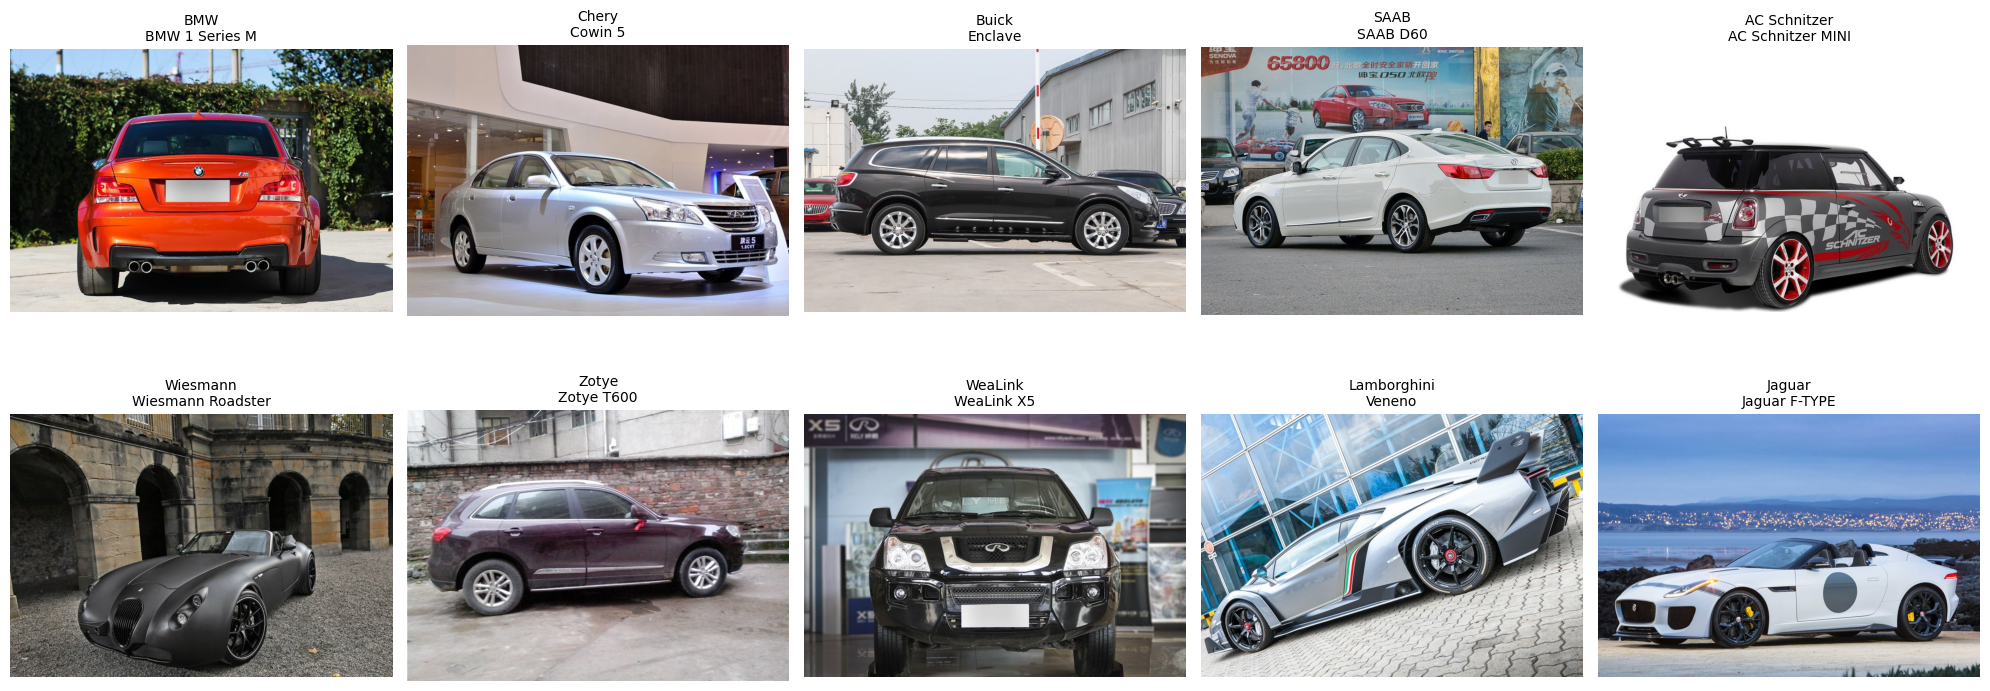

In [10]:
import matplotlib.pyplot as plt

fixed = ['BMW', 'Chery', 'Buick', 'SAAB', 'AC Schnitzer', 'Wiesmann', 'Zotye', 'WeaLink', 'Lamborghini', 'Jaguar']
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, mk in zip(axes.flatten(), fixed):
    sub = v2[v2['make'] == mk]
    if sub.empty:
        ax.set_title(f'{mk}: no rows'); ax.axis('off'); continue
    r = sub.sample(1, random_state=2).iloc[0]
    ax.imshow(Image.open(r['file_path']))
    ax.set_title(f"{r['make']}\n{r['model_name']}", fontsize=10)
    ax.axis('off')
plt.tight_layout(); plt.show()

In [11]:
sv = pd.read_csv(f'{out_dir}/compcars_surveillance_inventory_v2.csv')
print(sv['make'].value_counts().sort_index().to_string())

sample = sv.groupby('make', group_keys=False).apply(lambda g: g.sample(min(3, len(g)), random_state=1))
bad = []
for _, r in sample.iterrows():
    try:
        with Image.open(r['file_path']) as im:
            im.verify()
    except Exception as e:
        bad.append((r['make'], r['file_path']))
print(f"Checked {len(sample)} images. Failures: {len(bad)}")

make
Acura                599
Audi                 571
BMW                 1678
BYD                 1177
Baojun               165
Benz                1810
Besturn              110
Buick                740
Cadillac             492
Changan              755
Changhe               75
Chery                181
Chevy               1206
Chrysler             223
Citroen              793
Dodge                 38
Dongfengfengdu        92
Dongfengfengshen      53
Everus                50
FIAT                 316
Ford                 504
GAC                   80
Geely                576
GreatWall            494
Guangqichuanqi       514
Hafei                109
Haima                872
Haima(Zhengzhou)     172
Haval                246
Honda               2035
Huanghai              87
Huatai                71
Hyundai             1302
Infiniti             198
Jaguar               230
Jeep                 818
Jianghuai            920
Jinbei               113
KIA                  709
Karry               

/tmp/ipykernel_3671/1090885663.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sample = sv.groupby('make', group_keys=False).apply(lambda g: g.sample(min(3, len(g)), random_state=1))


Checked 204 images. Failures: 0
